### 1. importuri si setari initiale

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

### 2. incarcarea si afisarea datelor

In [25]:
housing = pd.read_csv('AmesHousing.csv', sep='\t')
housing.columns = housing.columns.str.replace(' ', '').str.replace('_', '')

display(housing.head())
display(housing.describe())

,Order,PID,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


,Order,PID,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemod/Add,MasVnrArea,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,2930.00000,2.930000e+03,2930.000000,2440.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2907.000000,...,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1465.50000,7.144645e+08,57.387372,69.224590,10147.921843,6.094881,5.563140,1971.356314,1984.266553,101.896801,...,93.751877,47.533447,23.011604,2.592491,16.002048,2.243345,50.635154,6.216041,2007.790444,180796.060068
std,845.96247,1.887308e+08,42.638025,23.365335,7880.017759,1.411026,1.111537,30.245361,20.860286,179.112611,...,126.361562,67.483400,64.139059,25.141331,56.087370,35.597181,566.344288,2.714492,1.316613,79886.692357
min,1.00000,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,733.25000,5.284770e+08,20.000000,58.000000,7440.250000,5.000000,5.000000,1954.000000,1965.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,1465.50000,5.354536e+08,50.000000,68.000000,9436.500000,6.000000,5.000000,1973.000000,1993.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2197.75000,9.071811e+08,70.000000,80.000000,11555.250000,7.000000,6.000000,2001.000000,2004.000000,164.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213500.000000
max,2930.00000,1.007100e+09,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,...,1424.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


### 3. organizarea si filtrarea datelor

In [26]:
num_cols = housing.select_dtypes(include=np.number).columns
cat_cols = housing.select_dtypes(exclude=np.number).columns

case_istorice = housing[housing['YearBuilt'] < 1920]
display(case_istorice[['YearBuilt', 'Neighborhood', 'OverallQual', 'SalePrice']].head())

,YearBuilt,Neighborhood,OverallQual,SalePrice
169,1900,OldTown,4,80400
170,1910,OldTown,4,96500
174,1915,OldTown,3,107400
183,1900,OldTown,8,150000
184,1915,OldTown,5,139000


### 4. rezolvarea datelor lipsa

In [ ]:
housing[num_cols] = housing[num_cols].fillna(housing[num_cols].median())
housing[cat_cols] = housing[cat_cols].fillna("None")

### 5. vizualizarea datelor 

### graficul 1


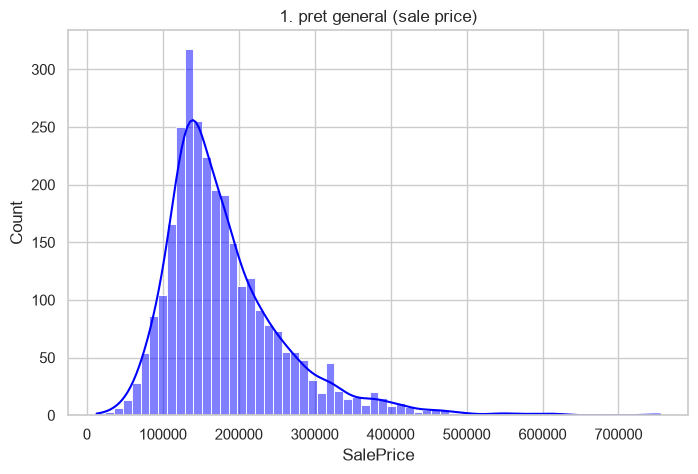

In [28]:
# intrebarea 1: care este pretul general ?
plt.figure(figsize=(8, 5))
sns.histplot(housing['SalePrice'], kde=True, color='blue')
plt.title('1. pret general (sale price)')
plt.show()

### graficul 2

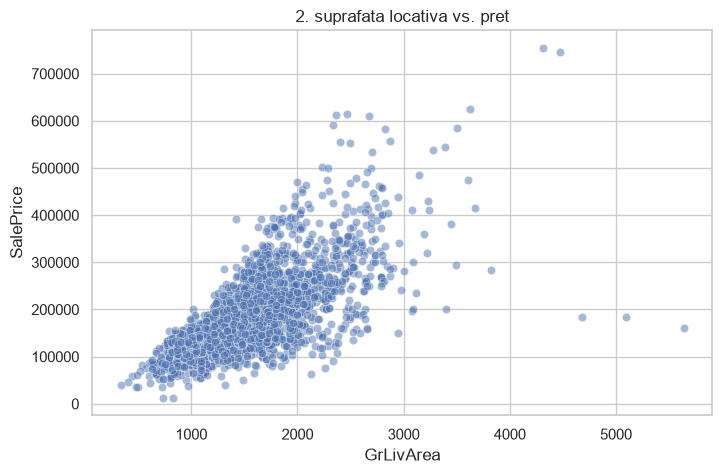

In [29]:
# intrebarea 2: casele cu o suprafata mai mare sunt mai scumpe?
plt.figure(figsize=(8, 5))
sns.scatterplot(data=housing, x='GrLivArea', y='SalePrice', alpha=0.5)
plt.title('2. suprafata locativa vs. pret')
plt.show()

### graficul 3


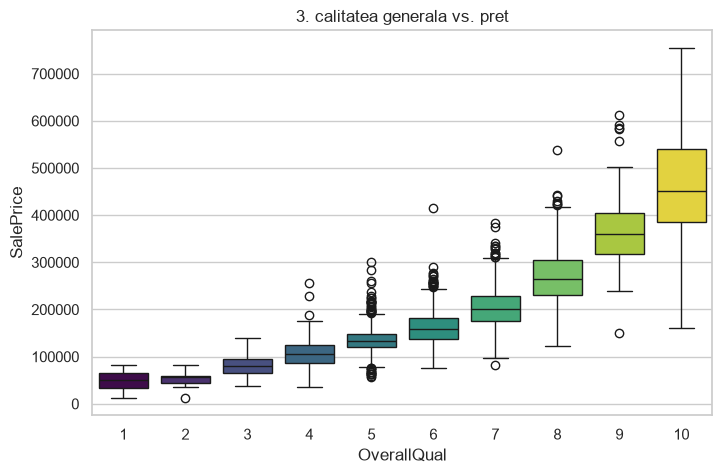

In [30]:
# intrebarea 3: cat de mult influenteaza calitatea generala (nota 1-10) pretul?
plt.figure(figsize=(8, 5))
sns.boxplot(data=housing, x='OverallQual', y='SalePrice', hue='OverallQual', legend=False, palette='viridis')
plt.title('3. calitatea generala vs. pret')
plt.show()

### graficul 4

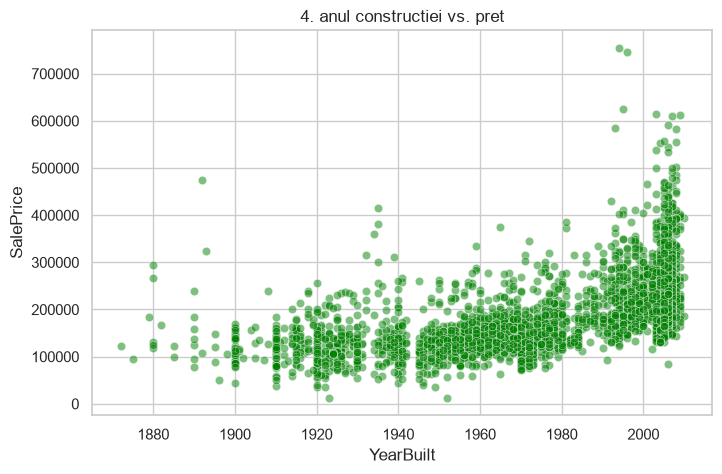

In [31]:
# intrebarea 4: casele mai noi sunt mai scumpe decat cele vechi?
plt.figure(figsize=(8, 5))
sns.scatterplot(data=housing, x='YearBuilt', y='SalePrice', alpha=0.5, color='green')
plt.title('4. anul constructiei vs. pret')
plt.show()

### graficul 5

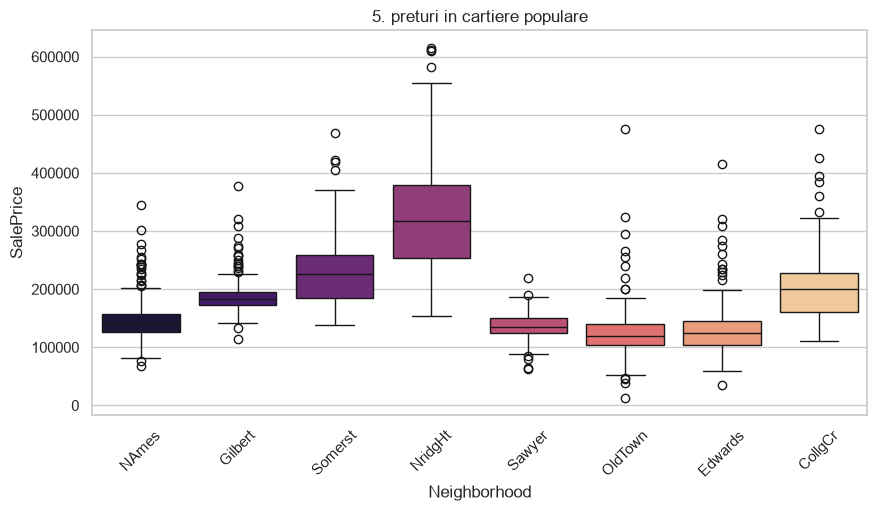

In [32]:
# intrebarea 5: cum difera preturile in top 8 cele mai populare cartiere?
plt.figure(figsize=(10, 5))
top_neighborhoods = housing['Neighborhood'].value_counts().index[:8]
sns.boxplot(data=housing[housing['Neighborhood'].isin(top_neighborhoods)], x='Neighborhood', y='SalePrice', hue='Neighborhood', legend=False, palette='magma')
plt.xticks(rotation=45)
plt.title('5. preturi in cartiere populare')
plt.show()

### graficul 6

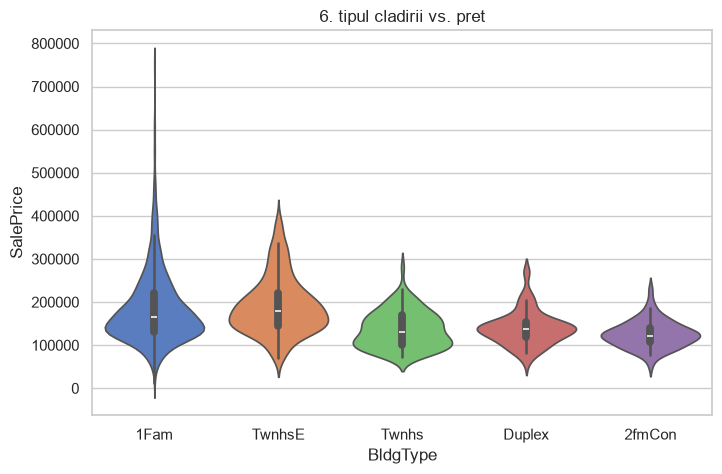

In [33]:
# intrebarea 6: ce tip de cladire (ex: single-family vs duplex) este mai scump?
plt.figure(figsize=(8, 5))
sns.violinplot(data=housing, x='BldgType', y='SalePrice', hue='BldgType', legend=False, palette='muted')
plt.title('6. tipul cladirii vs. pret')
plt.show()

### graficul 7

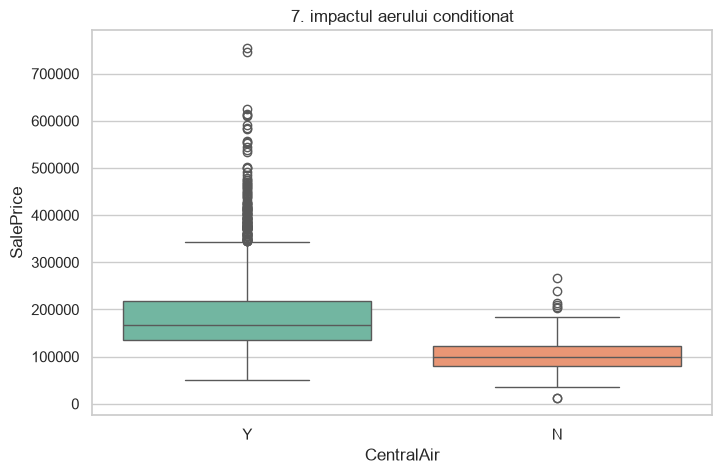

In [34]:
# intrebarea 7: adauga la pret aerul conditionat centralizat?(y/n)
plt.figure(figsize=(8, 5))
sns.boxplot(data=housing, x='CentralAir', y='SalePrice', hue='CentralAir', legend=False, palette='Set2')
plt.title('7. impactul aerului conditionat')
plt.show()

### graficul 8

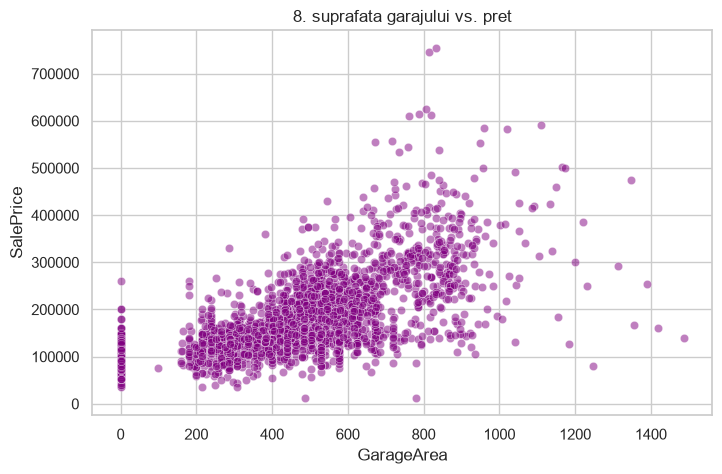

In [35]:
# intrebarea 8: exista o relatie clara intre suprafata garajului si pret?
plt.figure(figsize=(8, 5))
sns.scatterplot(data=housing, x='GarageArea', y='SalePrice', alpha=0.5, color='purple')
plt.title('8. suprafata garajului vs. pret')
plt.show()

### graficul 9

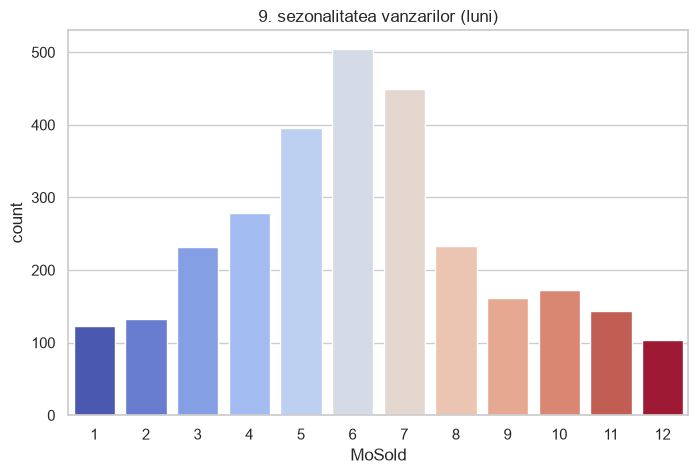

In [36]:
# intrebarea 9: in ce luna se vand cele mai multe case (sezonalitate)?
plt.figure(figsize=(8, 5))
sns.countplot(data=housing, x='MoSold', hue='MoSold', legend=False, palette='coolwarm')
plt.title('9. sezonalitatea vanzarilor (luni)')
plt.show()

### 6. heatmap (corelatia atributelor cu pretul)

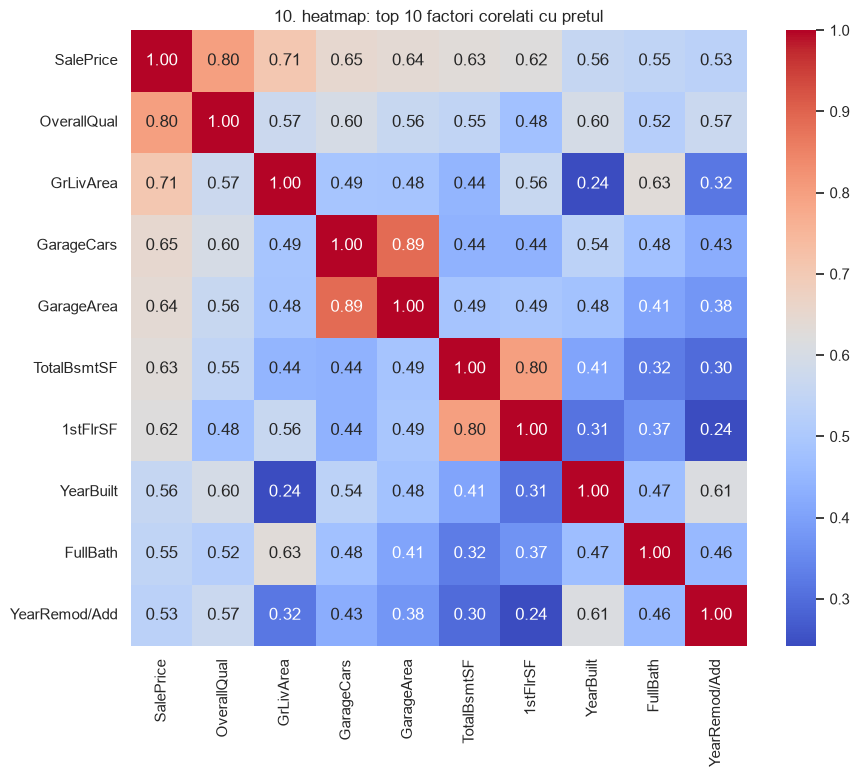

In [37]:
plt.figure(figsize=(10, 8))
top_corr_features = housing[num_cols].corr()['SalePrice'].sort_values(ascending=False).head(10).index
corr_matrix = housing[top_corr_features].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", square=True)
plt.title('10. heatmap: top 10 factori corelati cu pretul')
plt.show()